In [1]:
   import sys; from pathlib import Path
   sys.path.insert(0, str(Path.cwd().parent))
   from src.data import build_table
   df = build_table()

In [3]:
df.columns.tolist()

['match_id',
 'zone',
 'seats',
 'season_tickets',
 'season',
 'match_date',
 'time',
 'weekday',
 'opponent',
 'opponent_khl',
 'sales_open',
 'part',
 'hour',
 'month',
 'is_weekend',
 'is_test',
 'capacity',
 'sold_as_of',
 'sold_last_7d',
 'sold_last_14d',
 'sales_started',
 'days_to_match',
 'days_since_open',
 'tickets_total']

In [4]:
   train = df[df["is_test"] == 0].copy()
   train.shape

(680, 24)

In [8]:
print(df.shape)
df.isna().sum()

(816, 24)


match_id             0
zone                 0
seats                0
season_tickets       0
season               0
match_date           0
time                 0
weekday              0
opponent             0
opponent_khl         0
sales_open           0
part                 0
hour                 0
month                0
is_weekend           0
is_test              0
capacity             0
sold_as_of           0
sold_last_7d         0
sold_last_14d        0
sales_started        0
days_to_match        0
days_since_open      0
tickets_total      136
dtype: int64

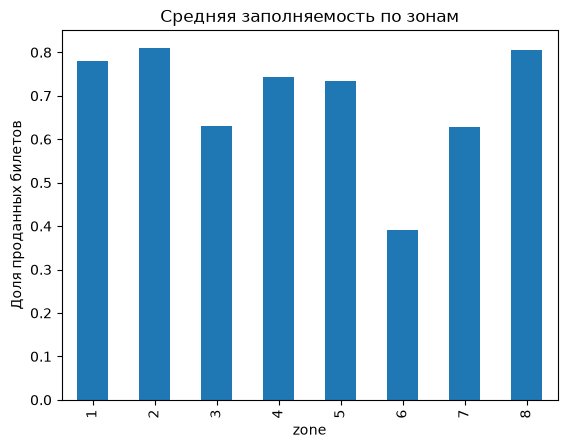

In [6]:
   import matplotlib.pyplot as plt
   train["fill_rate"] = train["tickets_total"] / train["capacity"]
   train.groupby("zone")["fill_rate"].mean().plot(kind="bar")
   plt.title("Средняя заполняемость по зонам")
   plt.ylabel("Доля проданных билетов")
   plt.show()

**Вывод:** зоны 1, 2 и 8 заполняются лучше всего (около 80%), а зона 6 — хуже всех (около 39%), заметно ниже остальных.

In [7]:
train.groupby("zone")[["seats", "season_tickets", "capacity", "tickets_total"]].mean().round(0)

,seats,season_tickets,capacity,tickets_total
zone,,,,
1,1141.0,545.0,596.0,465.0
2,528.0,148.0,380.0,308.0
3,1386.0,385.0,1001.0,633.0
4,1340.0,287.0,1053.0,782.0
5,1511.0,466.0,1044.0,767.0
6,1448.0,200.0,1248.0,487.0
7,1434.0,186.0,1248.0,781.0
8,682.0,120.0,562.0,450.0


**Вывод:** зона 6 заполняется хуже всех (около 39%). При этом по вместимости она не отличается от зоны 7 (по 1248 мест), но продаёт в среднем 487 билетов против 781. Причина по данным неясна (нет информации о ценах и расположении)Больше всего билетов в абсолютных числах продают зоны 4, 5 и 7 (около 770-780 на матч).

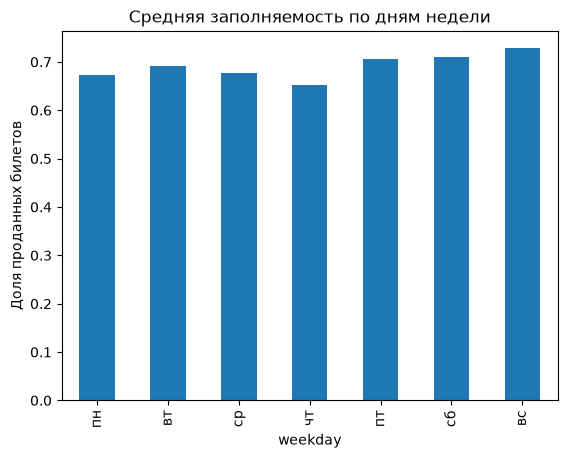

weekday
пн    12
вт     9
ср    15
чт    13
пт    11
сб    13
вс    12
Name: match_id, dtype: int64


In [9]:
days = {1: "пн", 2: "вт", 3: "ср", 4: "чт", 5: "пт", 6: "сб", 7: "вс"}

by_day = train.groupby("weekday")["fill_rate"].mean()
by_day.index = by_day.index.map(days)
by_day.plot(kind="bar")
plt.title("Средняя заполняемость по дням недели")
plt.ylabel("Доля проданных билетов")
plt.show()

# сколько матчей в каждый день, чтобы не делать выводы по 1-2 матчам
print(train.groupby("weekday")["match_id"].nunique().rename(index=days))

**Вывод:** день недели влияет на заполняемость слабо: все дни лежат в диапазоне примерно 65-73%. Лучше всего заполняются выходные и пятница (воскресенье около 73%, суббота и пятница около 71%), хуже всего четверг (около 65%). 

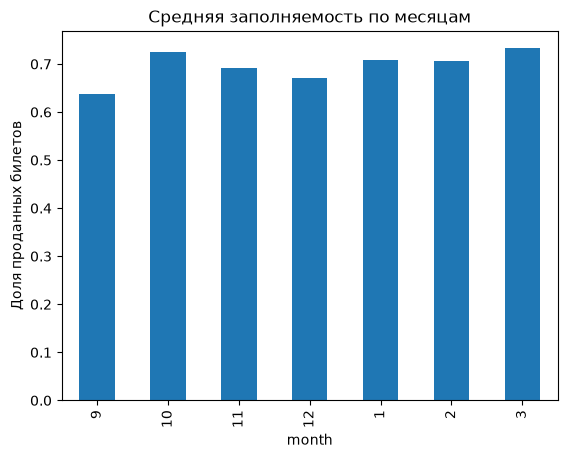

In [10]:
by_month = train.groupby("month")["fill_rate"].mean()
by_month = by_month.sort_index(key=lambda m: (m - 9) % 12)
by_month.plot(kind="bar")
plt.title("Средняя заполняемость по месяцам")
plt.ylabel("Доля проданных билетов")
plt.show()

**Вывод:** заполняемость по месяцам колеблется в узком диапазоне, примерно 64-73%, явного роста или падения в течение сезона нет. Надёжнее всего выделяется сентябрь (около 64%, 17 матчей): возможно, в начале сезона спрос ещё не разогрет, и здесь у клуба есть запас для маркетинга. Лучший из месяцев с достаточным числом матчей — октябрь (около 73%, 20 матчей). Март показывает около 73%, но матчей в нём всего 2, поэтому вывод по нему ненадёжен.